# Etapa II · Clasificación y clustering de artículos científicos

Un solo notebook con el **detalle de todos los experimentos**: qué se preguntó en cada
bloque, qué se dejó fijo, qué salió y qué se eligió.

| Tarea | Modelo final | Test |
|---|---|---|
| Supervisada | C02: N2 + TF-IDF (1,1) + LogisticRegression | macro-F1 **0.761** |
| No supervisada | K02: N2 + TF-IDF (1,1) + SVD 100 + KMeans(k=4) | silhouette **0.083**, ARI **0.372**, NMI **0.486** |

Todo se lee de los resultados congelados: **no se vuelve a tocar test**.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig")
import sys
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Normalizer
from IPython.display import display, Image

from src.etapa2.classify import make_vectorizer
from src.etapa2.labels import load_labeled
from src.etapa2.normalization import load_variants
from src.normalize import get_nlp, normalize_doc

pd.set_option("display.width", 180)

exp = pd.read_csv(ROOT / "results/etapa2/experiments.tsv", sep="\t",
                  dtype=str, keep_default_na=False)
metrics = pd.read_csv(ROOT / "results/etapa2/classification_metrics.tsv", sep="\t")
per_class = pd.read_csv(ROOT / "results/etapa2/classification_per_class.tsv", sep="\t")
cluster_summary = pd.read_csv(ROOT / "results/etapa2/cluster_summary.tsv", sep="\t")
assignments = pd.read_csv(ROOT / "results/etapa2/clustering_results.tsv", sep="\t",
                          dtype=str, keep_default_na=False)

def get(experiment_id):
    return exp[exp["experiment_id"] == experiment_id].iloc[0]

def dev_f1(experiment_id):
    row = get(experiment_id)
    return round(float(row["dev_metric"].split("macro_f1=")[1].split(";")[0]), 4)

def cv_f1(experiment_id):
    return round(float(get(experiment_id)["cv_macro_f1"]), 4)

def sil(experiment_id):
    return round(float(get(experiment_id)["dev_metric"].split("=")[1]), 4)

def extra(experiment_id):
    return dict(part.split("=", 1) for part in get(experiment_id)["extra"].split("; "))

def ari(experiment_id):
    return round(float(extra(experiment_id)["ari_dev"]), 4)

def stability(experiment_id):
    return round(float(extra(experiment_id)["stability_ari"].split("±")[0]), 4)

def sizes(experiment_id):
    return extra(experiment_id)["sizes"]

print("Experimentos:", len(exp), "| clasificación:", len(exp[exp.task == "classification"]),
      "| clustering:", len(exp[exp.task == "clustering"]))


Experimentos: 46 | clasificación: 29 | clustering: 17


## 0. La receta de un experimento

```text
normalización N0/N1/N2
  → representación binaria / frecuencia / TF-IDF
  → [SVD opcional]
  → clasificador (supervisado) o KMeans (no supervisado)
```

Cada experimento se ajusta solo con train, se evalúa en dev y se registra en
`experiments.tsv`. Test se usa una sola vez con el modelo final.

- **N0:** solo tokenizar.
- **N1:** minúsculas, sin puntuación ni stopwords.
- **N2:** minúsculas, lemas y filtro POS.
- **TF-IDF:** pesa las palabras por frecuencia e importancia.
- **SVD:** comprime la representación a 50/100/200 componentes.


## 0.1 Particiones train/dev/test

Los splits se fijan **antes** de ajustar vectorizadores, SVD o modelos, con dos cortes
estratificados de `train_test_split` (`shuffle=True`, `random_state=0`):

```text
500 documentos ──70/30──> train (350) + resto (150) ──15/15──> dev (75) + test (75)
```

- **train:** ajuste de vocabulario, IDF, SVD y modelos (y validación cruzada).
- **dev:** comparar experimentos y elegir configuración.
- **test:** se usa **una sola vez**, con el modelo final.

La partición queda guardada en la columna `split` de `data/etapa2/labeled_documents.tsv`
(`python -m src.etapa2.labels`). Aquí se recalcula para comprobar que es reproducible.

¿Reproducible con random_state=0? True


split,train,dev,test,Total
label,,,,
cs.CL,87,19,19,125
cs.CV,87,19,19,125
cs.IR,88,18,19,125
cs.LG,88,19,18,125
Total,350,75,75,500


split,train,dev,test
% del corpus,70.0,15.0,15.0


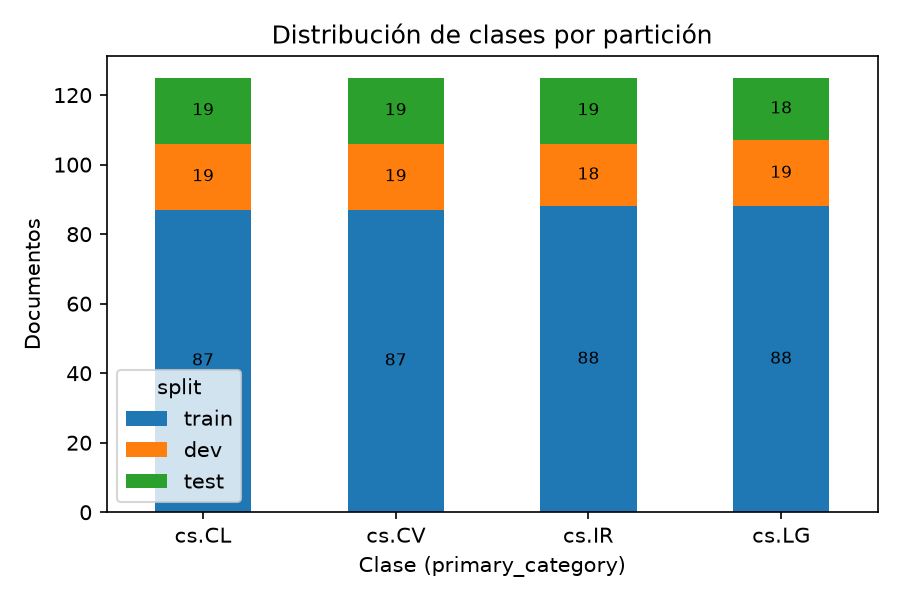

In [2]:
from src.etapa2.splits import assign_splits, check_splits

labeled = load_labeled()
recomputed = assign_splits(labeled)
print("¿Reproducible con random_state=0?", (recomputed == labeled["split"]).all())

table = check_splits(labeled)  # falla si alguna clase falta en alguna partición
table.loc["Total"] = table.sum()
table["Total"] = table.sum(axis=1)
display(table)
display((table.loc["Total", ["train", "dev", "test"]] / len(labeled) * 100)
        .round(1).rename("% del corpus").to_frame().T)
display(Image(filename=str(ROOT / "results/etapa2/figures/class_distribution.png")))

**Lectura:** 350/75/75 documentos (70/15/15) y las cuatro clases presentes en las tres
particiones, con 18–19 documentos por clase en dev y test. Todo lo que aprende de los datos
va dentro de un `Pipeline` que se ajusta solo con train, así que dev y test no filtran
información. Con 75 documentos en dev, **un documento ≈ 1.3 puntos** de macro-F1; por eso
también se reporta el macro-F1 de validación cruzada en train.

## 1. Supervisado

### C-1 · ¿Qué clasificador parte mejor?

**Fijo:** N2, TF-IDF, unigramas, sin SVD.

In [3]:
display(pd.DataFrame([
    {"Modelo": "MultinomialNB", "Exp.": "C01", "Dev": dev_f1("C01"), "CV": cv_f1("C01")},
    {"Modelo": "LogisticRegression", "Exp.": "C02", "Dev": dev_f1("C02"), "CV": cv_f1("C02")},
    {"Modelo": "SVC", "Exp.": "C03", "Dev": dev_f1("C03"), "CV": cv_f1("C03")},
]))

,Modelo,Exp.,Dev,CV
0,MultinomialNB,C01,0.7607,0.7594
1,LogisticRegression,C02,0.7993,0.7675
2,SVC,C03,0.7481,0.7478


**Lectura:** LR es el mejor en dev y CV; NB es competitivo con la mitad del
vocabulario; SVC queda abajo. Las diferencias en CV son pequeñas, así que los tres pasan
a C-2.

### C-2 · ¿Cuánto ayuda normalizar?

**Fijo:** TF-IDF, unigramas, sin SVD. Cambia N0/N1/N2.

In [4]:
models = [("MultinomialNB", ["C04", "C07", "C01"]),
          ("LogisticRegression", ["C05", "C08", "C02"]),
          ("SVC", ["C06", "C09", "C03"])]
rows = []
for model, ids in models:
    rows.append({"Modelo": model,
                 "N0": dev_f1(ids[0]), "N1": dev_f1(ids[1]), "N2": dev_f1(ids[2])})
display(pd.DataFrame(rows))

,Modelo,N0,N1,N2
0,MultinomialNB,0.7046,0.7745,0.7607
1,LogisticRegression,0.7602,0.7981,0.7993
2,SVC,0.7742,0.7613,0.7481


**Lectura:**
- **NB** es el más sensible: N1 le da 0.7745 y N0 0.7046.
- **LR** prefiere N2: 0.7993; N1 queda en 0.7981.
- **SVC** es casi insensible en CV; N0 gana por 2 documentos (0.7742).

Cada modelo se queda con **su** mejor normalización.

### C-3 · ¿Binaria, frecuencia o TF-IDF?

**Fijo:** la mejor normalización de cada modelo, unigramas, sin SVD.

In [5]:
models = [("NB (N1)", ["C10", "C11", "C07"]),
          ("LR (N2)", ["C12", "C13", "C02"]),
          ("SVC (N0)", ["C14", "C15", "C06"])]
rows = []
for model, ids in models:
    rows.append({"Modelo": model, "Binaria": dev_f1(ids[0]),
                 "Frecuencia": dev_f1(ids[1]), "TF-IDF": dev_f1(ids[2])})
display(pd.DataFrame(rows))

,Modelo,Binaria,Frecuencia,TF-IDF
0,NB (N1),0.7049,0.7327,0.7745
1,LR (N2),0.7445,0.7457,0.7993
2,SVC (N0),0.7466,0.6624,0.7742


**Lectura:** TF-IDF gana en los tres. La frecuencia pura se hunde en SVC
(0.6624). TF-IDF baja el peso de palabras que están en casi todos los abstracts y sube el
de las que distinguen un área.

### C-4 · ¿Bigramas o trigramas?

**Fijo:** TF-IDF y la mejor normalización por modelo.

In [6]:
models = [("NB", ["C07", "C16", "C17"]),
          ("LR", ["C02", "C18", "C19"]),
          ("SVC", ["C06", "C20", "C21"])]
rows = []
for model, ids in models:
    rows.append({"Modelo": model, "(1,1)": dev_f1(ids[0]),
                 "(1,2)": dev_f1(ids[1]), "(1,3)": dev_f1(ids[2])})
display(pd.DataFrame(rows))

,Modelo,"(1,1)","(1,2)","(1,3)"
0,NB,0.7745,0.7673,0.7554
1,LR,0.7993,0.8007,0.7751
2,SVC,0.7742,0.7458,0.7566


**Lectura:** no hay mejora material. LR con bigramas gana por 0.0014 (una décima
de documento) y con trigramas baja; NB y SVC empeoran. El vocabulario de SVC crece de
9 974 a 145 406 rasgos.

### C-5 · ¿Ayuda el SVD?

**Fijo:** la mejor configuración de cada modelo; solo LR y SVC, porque NB no admite
valores negativos.

In [7]:
rows = [
    {"Modelo": "LR", "Sin SVD": dev_f1("C02"), "SVD 50": dev_f1("C28"),
     "SVD 100": dev_f1("C26"), "SVD 200": dev_f1("C27")},
    {"Modelo": "SVC", "Sin SVD": dev_f1("C06"), "SVD 50": dev_f1("C29"),
     "SVD 100": dev_f1("C24"), "SVD 200": dev_f1("C25")},
]
display(pd.DataFrame(rows))
print("C22/C23 usan SVD sobre bigramas (C18):", dev_f1("C22"), "/", dev_f1("C23"))

,Modelo,Sin SVD,SVD 50,SVD 100,SVD 200
0,LR,0.7993,0.7706,0.7586,0.7475
1,SVC,0.7742,0.7880,0.7504,0.7751


C22/C23 usan SVD sobre bigramas (C18): 0.7573 / 0.7713


**Lectura:**
- **LR:** el SVD no ayuda en ninguna dimensión; todo baja de 0.7993.
- **SVC:** SVD 50 sube a 0.7880 en dev, pero su CV es 0.7040 frente a 0.7451.
  C29 se añadió después de congelar test; no se re-evaluó. Se mantiene C06.
- C22/C23 (SVD sobre bigramas) también quedan debajo de C18 (0.8007).

### Selección y test

| Modelo | Se queda con | Dev | CV |
|---|---|---:|---:|
| NB | C07 (N1) | 0.7745 | 0.7612 |
| LR | C02 (N2) | **0.7993** | 0.7675 |
| SVC | C06 (N0) | 0.7742 | 0.7451 |

Ganador global: **C02**. Se reajusta con train+dev y se evalúa **una vez** en test.

,experiment_id,model,split,accuracy,macro_precision,macro_recall,macro_f1
3,test,LogisticRegression,test,0.76,0.7675,0.7617,0.761


,experiment_id,model,split,label,precision,recall,f1,support
12,test,LogisticRegression,test,cs.CL,0.5789,0.5789,0.5789,19
13,test,LogisticRegression,test,cs.CV,0.8750,0.7368,0.8000,19
14,test,LogisticRegression,test,cs.IR,0.8889,0.8421,0.8649,19
15,test,LogisticRegression,test,cs.LG,0.7273,0.8889,0.8000,18


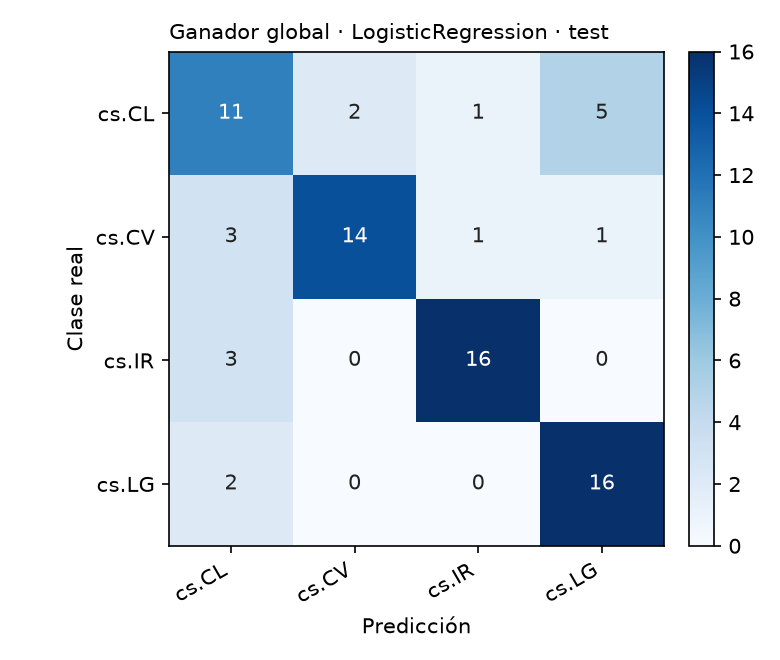

In [8]:
display(metrics[metrics["split"] == "test"].round(4))
display(per_class[per_class["split"] == "test"].round(4))
display(Image(filename=str(ROOT / "results/etapa2/confusion_matrices/test.png")))

**Lectura:** accuracy 0.760 y macro-F1 0.761. La clase más difícil es `cs.CL`
(F1 0.579); `cs.CV` y `cs.IR` llegan a 0.800 y 0.865. La confusión principal es
`cs.CL` ↔ `cs.LG`.

## 2. No supervisado

### K-1 · ¿Cuántos clusters?

**Fijo:** N2, TF-IDF, SVD 100. Sin etiquetas.

In [9]:
rows = []
for eid in ["K01", "K02", "K03", "K04", "K05"]:
    k = int(get(eid)["hyperparameters"].split("k=")[1].split(";")[0])
    rows.append({"k": k, "Exp.": eid, "Silhouette dev": sil(eid),
                 "ARI dev": ari(eid), "Estabilidad": stability(eid),
                 "Tamaños train": sizes(eid)})
display(pd.DataFrame(rows))

,k,Exp.,Silhouette dev,ARI dev,Estabilidad,Tamaños train
0,3,K01,0.0651,0.2854,0.2671,37-164-149
1,4,K02,0.0660,0.3755,0.2335,102-133-67-48
2,5,K03,0.0609,0.3375,0.2228,100-71-31-64-84
3,6,K04,0.0645,0.2954,0.2347,39-82-93-42-66-28
4,8,K05,0.0664,0.2633,0.2123,63-24-33-74-55-50-35-16


**Lectura:** el silhouette es casi plano (0.0609--0.0664); k=8 gana por 0.0004
y k=4 queda segundo. La estabilidad favorece k=3, pero sus tamaños son 37/164/149. Se elige
**k=4 (K02)** por interpretabilidad y equilibrio: 4 clusters temáticos.

### K-2 · ¿Normalización?

**Fijo:** k=4, TF-IDF, SVD 100.

In [10]:
rows = []
for eid, norm in [("K06", "N0"), ("K07", "N1"), ("K02", "N2")]:
    rows.append({"Normalización": norm, "Exp.": eid, "Silhouette dev": sil(eid),
                 "ARI dev": ari(eid), "Tamaños": sizes(eid)})
display(pd.DataFrame(rows))

,Normalización,Exp.,Silhouette dev,ARI dev,Tamaños
0,N0,K06,0.0986,0.0217,22-184-144
1,N1,K07,0.0546,0.3296,75-124-151
2,N2,K02,0.0660,0.3755,102-133-67-48


**Lectura:** N0 sube el silhouette a 0.0986, pero su ARI es 0.0217: separa
formato, no temas. N2 es el más interpretable (ARI 0.3755).

### K-3 · ¿Binaria, frecuencia o TF-IDF?

**Fijo:** k=4, N2, SVD 100.

In [11]:
rows = []
for eid, rep in [("K17", "Binaria"), ("K08", "Frecuencia"), ("K02", "TF-IDF")]:
    rows.append({"Representación": rep, "Exp.": eid, "Silhouette dev": sil(eid),
                 "ARI dev": ari(eid), "Tamaños": sizes(eid)})
display(pd.DataFrame(rows))

,Representación,Exp.,Silhouette dev,ARI dev,Tamaños
0,Binaria,K17,0.0477,-0.0038,121-126-103
1,Frecuencia,K08,0.1727,0.0427,143-111-96
2,TF-IDF,K02,0.0660,0.3755,102-133-67-48


**Lectura:** la binaria (K17) queda en 0.0477 y ARI −0.0038; no mejora.
Frecuencia sube el silhouette a 0.1727, pero su ARI es 0.0427. TF-IDF es el que deja
clusters temáticos.

### K-4 · ¿Unigramas o bigramas?

**Fijo:** k=4, N2, TF-IDF, SVD 100.

In [12]:
rows = []
for eid, ngram in [("K02", "Unigramas"), ("K09", "Bigramas")]:
    rows.append({"N-gramas": ngram, "Exp.": eid, "Silhouette dev": sil(eid),
                 "ARI dev": ari(eid), "Tamaños": sizes(eid)})
display(pd.DataFrame(rows))

,N-gramas,Exp.,Silhouette dev,ARI dev,Tamaños
0,Unigramas,K02,0.0660,0.3755,102-133-67-48
1,Bigramas,K09,0.1873,0.0349,100-106-144


**Lectura:** bigramas sube el silhouette a 0.1873, pero su ARI es 0.0349:
separa números y LaTeX. Se queda unigramas.

### K-5 · ¿SVD?

**Fijo:** k=4, N2, TF-IDF.

In [13]:
rows = []
for eid, svd in [("K10", "Sin SVD"), ("K11", "SVD 50"),
                 ("K02", "SVD 100"), ("K12", "SVD 200")]:
    rows.append({"SVD": svd, "Exp.": eid, "Silhouette dev": sil(eid),
                 "ARI dev": ari(eid), "Tamaños": sizes(eid)})
display(pd.DataFrame(rows))

,SVD,Exp.,Silhouette dev,ARI dev,Tamaños
0,Sin SVD,K10,0.0584,0.0605,151-85-114
1,SVD 50,K11,0.2085,0.0427,146-105-99
2,SVD 100,K02,0.0660,0.3755,102-133-67-48
3,SVD 200,K12,0.1684,0.0600,102-105-143


**Lectura:** SVD 50/200 inflan el silhouette con artefactos; SVD 100 es el que
mantiene clusters temáticos. Sin SVD también es peor (ARI 0.0605).

### K-6 · ¿Toca los hiperparámetros de K-Means?

**Fijo:** K02; cambia `init`, `n_init`, `max_iter`.

In [14]:
rows = []
for eid in ["K02", "K13", "K14", "K15", "K16"]:
    rows.append({"Exp.": eid, "Silhouette dev": sil(eid), "ARI dev": ari(eid),
                 "Estabilidad": stability(eid)})
display(pd.DataFrame(rows))

,Exp.,Silhouette dev,ARI dev,Estabilidad
0,K02,0.0660,0.3755,0.2335
1,K13,0.2085,0.0427,0.9869
2,K14,0.2085,0.0427,0.9850
3,K15,0.2085,0.0427,0.9835
4,K16,0.2085,0.0427,0.9883


**Lectura:** K13--K16 empatan en 0.2085; ninguna mejora real. K16 gana el
silhouette automático, pero sus clusters son de formato y se descarta. Se mantiene K02.

### La trampa del silhouette

Los bloques K-2 a K-6 suben el silhouette hasta 0.209, pero separan **LaTeX, números y
longitud**, no áreas; su ARI es ~0.04. El silhouette solo se compara dentro del mismo
espacio de características. Por eso K02 (N2, TF-IDF, SVD 100, k=4) es la final, con
silhouette bajo pero clusters temáticos.

,cluster_id,size,top_words
0,0,192,"training, task, language, token, datum, improv..."
1,1,156,"retrieval, evidence, item, recommendation, que..."
2,2,113,"video, image, visual, generation, scene, train..."
3,3,39,"parameter, training, learn, attention, cost, s..."


split,dev,test,train
cluster_id,,,
0,34,30,128
1,16,25,115
2,17,14,82
3,8,6,25


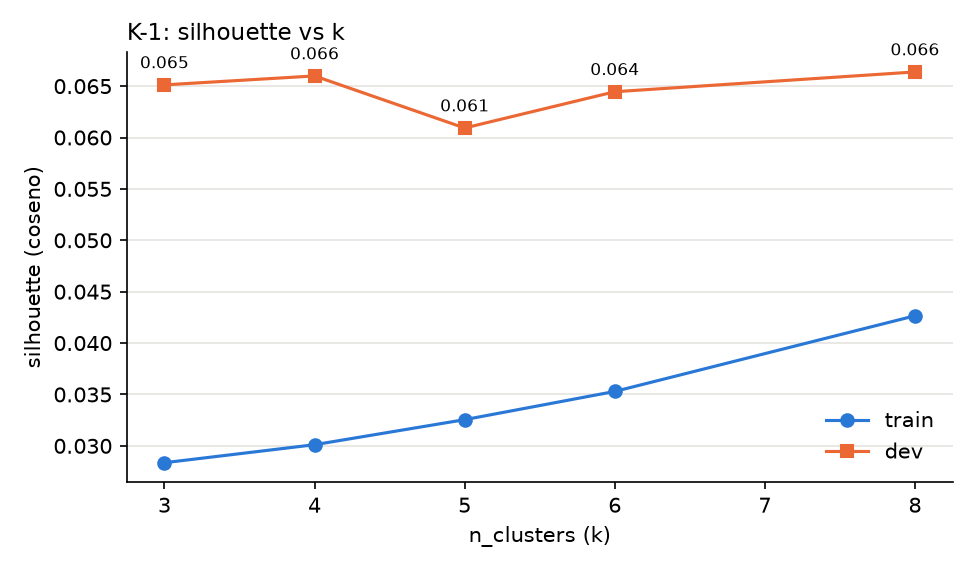

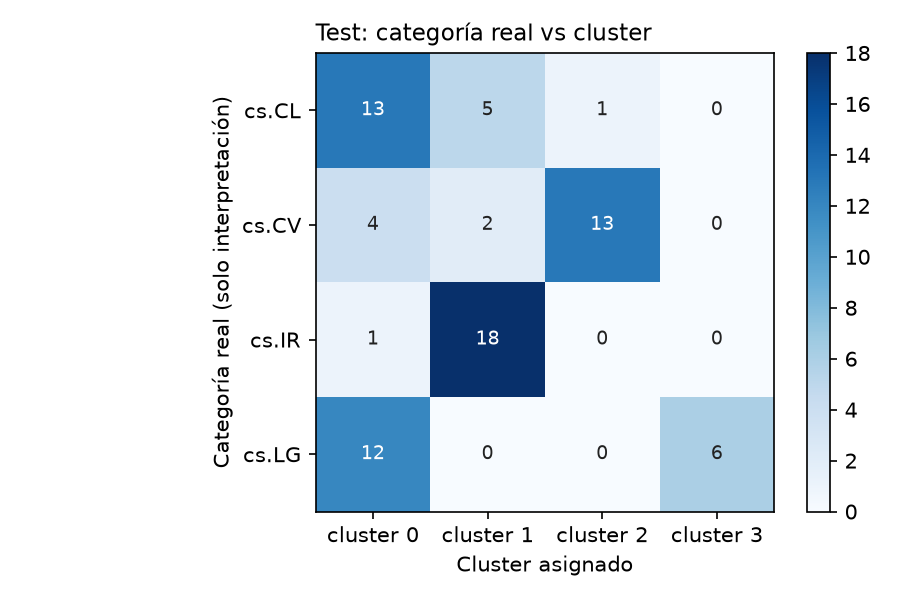

In [15]:
display(cluster_summary[["cluster_id", "size", "top_words"]])
display(pd.crosstab(assignments["cluster_id"], assignments["split"]))
display(Image(filename=str(ROOT / "results/etapa2/figures/clustering_silhouette_vs_k.png")))
display(Image(filename=str(ROOT / "results/etapa2/figures/clustering_contingency_test.png")))

**Interpretación:** cluster 0 = NLP/agentes (13 `cs.CL` + 12 `cs.LG`), cluster 1
= IR/recomendación (18 de 19 `cs.IR`), cluster 2 = visión/vídeo (13 de 19 `cs.CV`), cluster
3 = ML general (6 de 18 `cs.LG`, 39 documentos). ARI test 0.3719 y NMI 0.4860.

## 3. Guardar los modelos finales

Se reajustan C02 y K02 con train+dev y se guardan en `models/etapa2/`.

In [16]:
df = load_labeled()
texts = load_variants().set_index("document_id")["text_n2"]
train_dev = df[df["split"].isin(["train", "dev"])]
X = texts.loc[train_dev["document_id"]].tolist()
y = train_dev["label"].tolist()

clf = Pipeline([
    ("vec", make_vectorizer("tfidf", (1, 1))),
    ("clf", LogisticRegression(max_iter=2000, random_state=0)),
]).set_params(vec__min_df=1, clf__C=1.0)
clf.fit(X, y)

km = Pipeline([
    ("vec", make_vectorizer("tfidf", (1, 1))),
    ("svd", TruncatedSVD(n_components=100, random_state=0)),
    ("l2", Normalizer()),
    ("km", KMeans(n_clusters=4, init="k-means++", n_init=10,
                  max_iter=300, random_state=0)),
])
km.fit(X)

model_dir = ROOT / "models" / "etapa2"
model_dir.mkdir(parents=True, exist_ok=True)
joblib.dump({"pipeline": clf, "config": {
    "experiment": "C02", "normalization": "N2", "representation": "tfidf",
    "ngram_range": [1, 1], "C": 1.0, "min_df": 1,
}}, model_dir / "classifier_c02.pkl")
joblib.dump({"pipeline": km, "config": {
    "experiment": "K02", "normalization": "N2", "representation": "tfidf",
    "ngram_range": [1, 1], "svd_components": 100, "k": 4,
    "init": "k-means++", "n_init": 10, "max_iter": 300,
}}, model_dir / "kmeans_k02.pkl")

metadata = {
    "classifier": {"experiment": "C02", "normalization": "N2",
                   "representation": "tfidf", "ngram_range": [1, 1],
                   "C": 1.0, "min_df": 1,
                   "dev_macro_f1": 0.7993, "test_macro_f1": 0.7610},
    "kmeans": {"experiment": "K02", "normalization": "N2",
               "representation": "tfidf", "ngram_range": [1, 1],
               "svd_components": 100, "k": 4, "init": "k-means++",
               "n_init": 10, "max_iter": 300,
               "test_silhouette": 0.0829, "test_ari": 0.3719, "test_nmi": 0.4860},
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "random_state": 0,
}
with open(model_dir / "metadata.json", "w", encoding="utf-8") as fh:
    json.dump(metadata, fh, ensure_ascii=False, indent=2)

for path in sorted(model_dir.glob("*")):
    print(f"{path.name:22} {path.stat().st_size / 1024:8.1f} KB")

classifier_c02.pkl        389.6 KB
kmeans_k02.pkl           5969.6 KB
metadata.json               0.7 KB


## 4. Usar los modelos guardados

Los pipelines guardados reciben **texto ya normalizado** (N2). Para texto nuevo, normaliza
primero con `normalize_doc`.

In [17]:
clf_loaded = joblib.load(ROOT / "models/etapa2/classifier_c02.pkl")["pipeline"]
km_loaded = joblib.load(ROOT / "models/etapa2/kmeans_k02.pkl")["pipeline"]

sample = ("Retrieval-augmented generation for multi-hop question answering with "
          "large language models. We propose a retrieval pipeline that selects "
          "evidence documents and improves answer accuracy.")
norm = normalize_doc(get_nlp()(sample))
print("Normalizado:", norm[:110], "...")
print("Clase:", clf_loaded.predict([norm])[0])
print("Cluster:", int(km_loaded.predict([norm])[0]))

Normalizado: retrieval augment generation multi hop question answer large language model propose retrieval pipeline select  ...
Clase: cs.IR
Cluster: 1


## 5. Resumen

| Tarea | Configuración | Dev | Test |
|---|---|---|---|
| Clasificación | C02: N2 + TF-IDF (1,1) + LR(C=1) | 0.7993 | **0.7610** |
| Clustering | K02: N2 + TF-IDF (1,1) + SVD 100 + KMeans(k=4) | silhouette 0.0660 | **0.083** / ARI 0.372 / NMI 0.486 |

**46 experimentos** en total: 29 de clasificación y 17 de clustering.

```bash
python -m src.etapa2.cli metrics
python -m src.etapa2.cli clusters
python -m src.etapa2.cli experiments --task classification --top 10
```

Los modelos están en `models/etapa2/` y el informe completo en `Etapa2/informe.pdf`.